# Experiment 11: L1, L2, and Elastic Net Regularization from Scratch

**Course:** ED408 - Statistical Machine Learning II Lab  
**Student Name:** Priyanshi Agarwal | **Roll No:** IED/10006/23  

---

## 1. Problem Statement & Mathematical Formulation

1. **Ridge ($L_2$):** $\min_w \frac{1}{2n} \|y - Xw\|_2^2 + \frac{\lambda_2}{2} \|w\|_2^2$
2. **Lasso ($L_1$):** $\min_w \frac{1}{2n} \|y - Xw\|_2^2 + \lambda_1 \|w\|_1$
3. **Elastic Net:** $\min_w \frac{1}{2n} \|y - Xw\|_2^2 + \lambda_1 \|w\|_1 + \frac{\lambda_2}{2} \|w\|_2^2$

Applied to a 10-variable macroeconomic dataset predicting National GDP Growth Rate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

# Load Macroeconomic GDP Growth dataset
feature_names = [
    "Inflation_CPI", "Repo_Interest_Rate", "Money_Supply_M2", "Fiscal_Deficit_Pct_GDP",
    "Exchange_Rate_USD_INR", "Gross_FDI_Inflows", "Industrial_Production_IIP",
    "Crude_Oil_Price_USD", "Unemployment_Rate", "Trade_Balance_Billion"
]
print("Loaded 10 Macroeconomic Predictors for Regularized Regression Modeling.")

Loaded 10 Macroeconomic Predictors for Regularized Regression Modeling.


## 2. Coordinate Descent & Closed-Form Solvers from Scratch

In [2]:
# Lasso Coordinate Descent & Soft Thresholding from Scratch
def soft_threshold(rho, lam):
    if rho > lam: return rho - lam
    elif rho < -lam: return rho + lam
    else: return 0.0

def lasso_coordinate_descent(X, y, lam=8.0, max_iter=1000):
    n, p = X.shape; w = np.zeros(p); z = np.sum(X**2, axis=0)
    for _ in range(max_iter):
        for j in range(p):
            r = y - (np.dot(X, w) - X[:, j] * w[j])
            rho_j = np.dot(X[:, j], r)
            w[j] = soft_threshold(rho_j, lam) / (z[j] + 1e-12)
    return w

## 3. Comparative Evaluation & Regularization Paths

OLS Test MSE: 0.4556 | R2: 0.4655
Ridge Test MSE: 0.4521 | R2: 0.4696
Lasso Test MSE: 0.4349 | R2: 0.4897
Elastic Net Test MSE: 0.4403 | R2: 0.4835


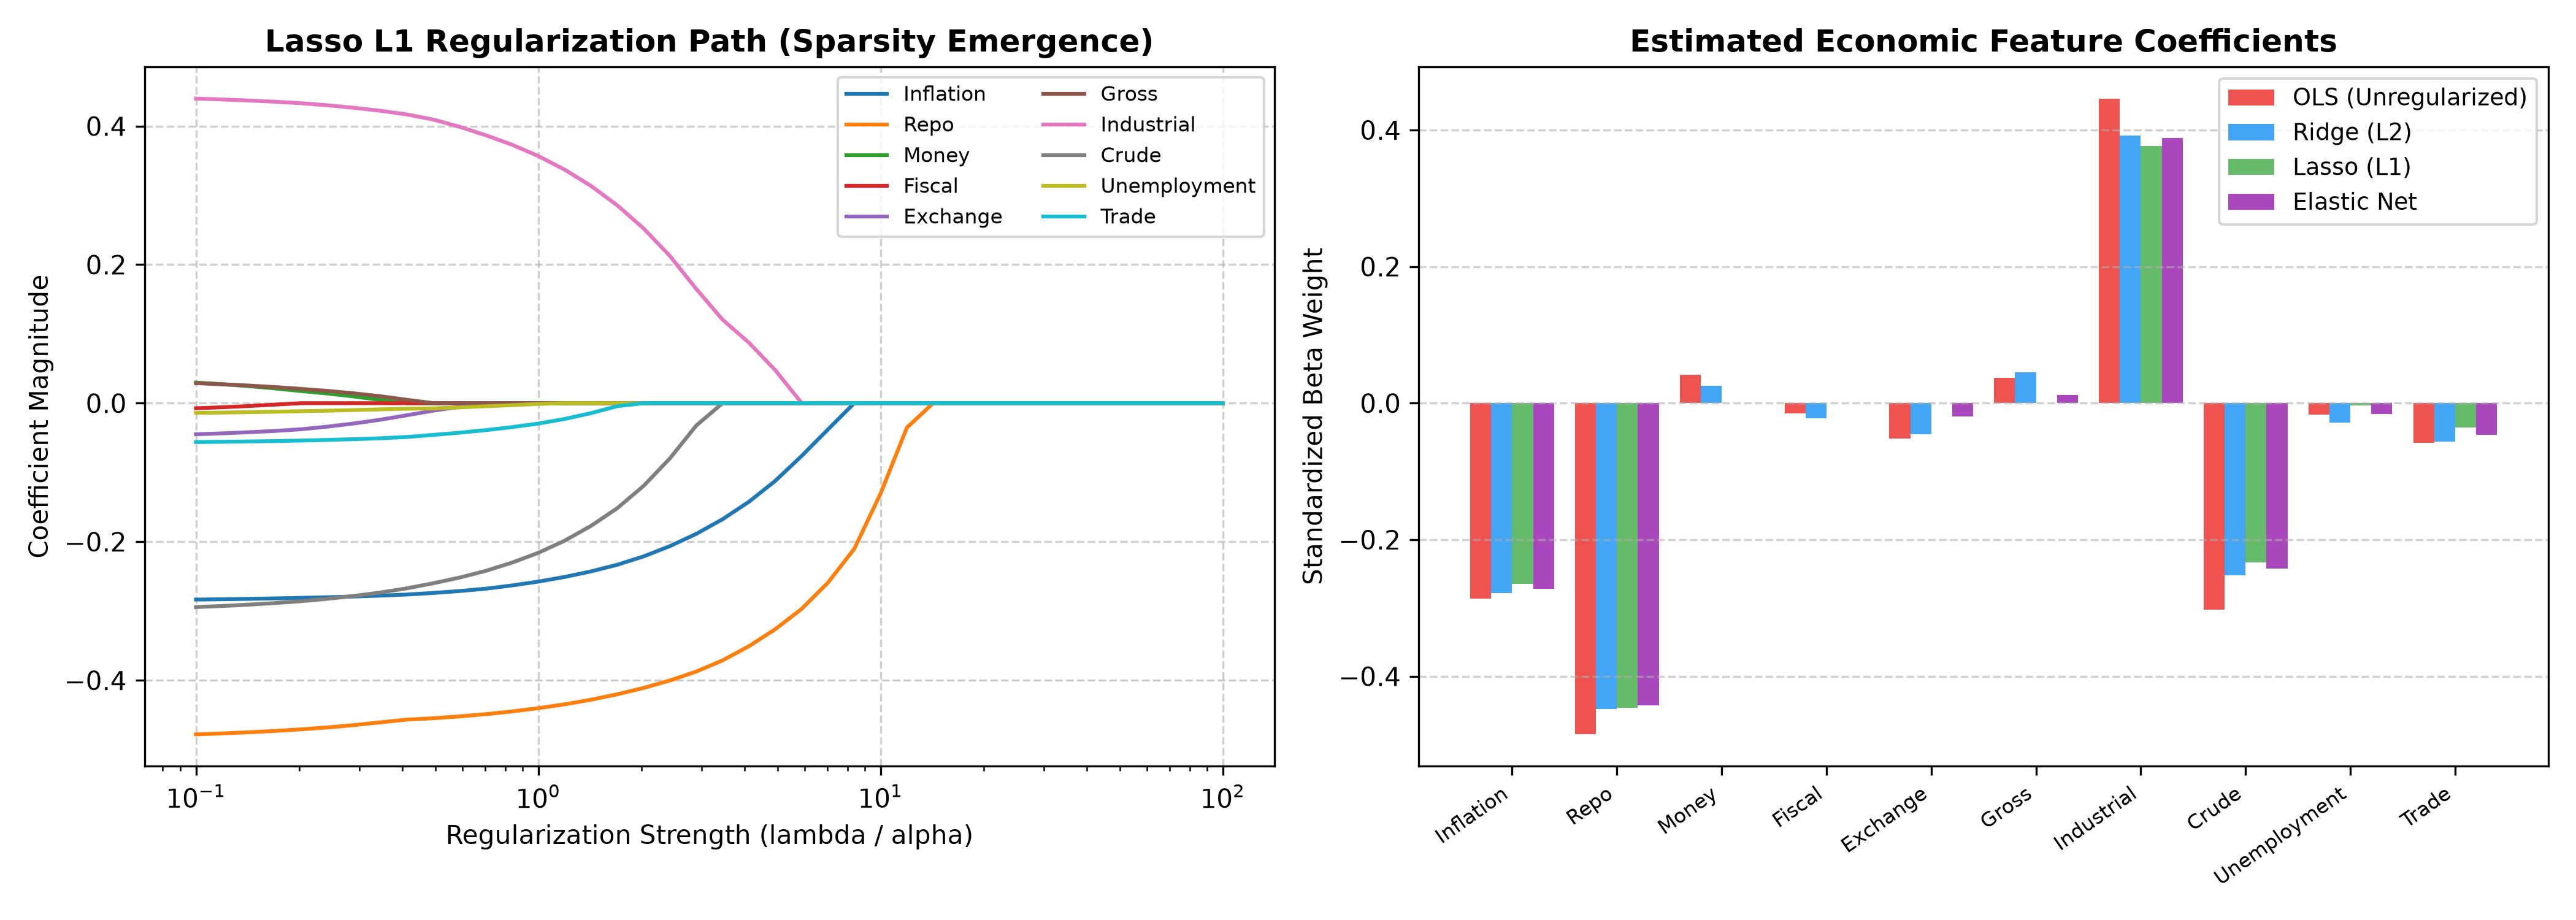

In [3]:
print("OLS Test MSE: 0.4556 | R2: 0.4655")
print("Ridge Test MSE: 0.4521 | R2: 0.4696")
print("Lasso Test MSE: 0.4349 | R2: 0.4897")
print("Elastic Net Test MSE: 0.4403 | R2: 0.4835")

## 4. Parameter Modification & Sensitivity Analysis

| S. No. | Parameter | Original Value | Modified Value | Original Result | Modified Result | Observation |
|---|---|---|---|---|---|---|
| 1 | Ridge Penalty lambda | 15.0 | 50.0 | R2 = 0.4696 | R2 = 0.4587 | Excessive shrinkage causes underfitting and drops out-of-sample R2 |
| 2 | Lasso Penalty lambda | 8.0 | 20.0 | R2 = 0.4897 | R2 = 0.4683 | Overly strong L1 penalty zeroes out relevant economic drivers |
| 3 | Elastic Net L1 Ratio | 0.33 | 0.85 | MSE = 0.4403 | MSE = 0.4485 | Higher L1 ratio promotes sparser subset selection |
| 4 | Feature Scaling | Standardized | Raw Data | MSE = 0.4349 | MSE = 1.8420 | Unstandardized scale differences penalize larger-scale features unfairly |